# Naira Pulse, Stage 1: Data Acquisition & Exploratory Analysis

**Project:** Naira Pulse, a classifier that forecasts short-term USD/NGN exchange rate risk to help Nigerian importers time dollar purchases.

**This notebook covers Stage 1 of 5:**

1. **Data Acquisition & EDA** (this notebook)
2. Feature Engineering & Target Definition
3. Modeling Pipeline
4. Evaluation & Backtesting
5. Packaging (executive summary, slides, video)

**What this notebook does:**
- Pulls raw, real-world data from Alpha Vantage: daily USD/NGN exchange rates, crude oil prices (WTI and Brent), and a US inflation series, all via free API calls, no Kaggle dataset involved.
- Caches every raw API response to disk before touching it, so repeated runs do not burn through the free tier's daily request limit.
- Cleans and merges everything into one master time series.
- Explores it: plots the rate over time, checks for missing data, looks at volatility, and checks how the rate correlates with oil prices.

**A note on scope:** Alpha Vantage's economic indicator endpoints (inflation, GDP, interest rates) are US-focused, sourced from FRED. There is no clean free API for Nigeria-side inflation or CBN interest rates, so those numbers get added manually in Stage 2 from Trading Economics or CBN's published releases, cited as a source rather than pulled programmatically. Worth a sentence in the executive summary's *Solution* section: it shows you understood the data landscape rather than assuming one API covers everything.


## 1. Setup

Get a free API key first: [alphavantage.co/support/#api-key](https://www.alphavantage.co/support/#api-key), no credit card, instant. Paste it into `API_KEY` below. Do not commit your real key to a public GitHub repo, when you push this notebook, either blank the key out or load it from an environment variable / Colab secret instead.

In [3]:
# Ensure required packages are installed in the notebook kernel's environment
import sys, subprocess
pkgs = ["requests", "numpy", "pandas", "matplotlib"]
for p in pkgs:
    try:
        __import__(p)
    except Exception:
        subprocess.check_call([sys.executable, "-m", "pip", "install", p])
print("Required packages are installed (or already present). Restart the kernel if prompted.")

Required packages are installed (or already present). Restart the kernel if prompted.


In [4]:
import os
import json
import time
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from google.colab import userdata
API_KEY = userdata.get('API_KEY')

RAW_DIR = "raw_data"
os.makedirs(RAW_DIR, exist_ok=True)

pd.set_option("display.max_columns", 100)

## 2. Fetch functions, with caching

Each function checks disk first. If the raw JSON has already been pulled, it loads that instead of calling the API again. This matters because the free tier is capped at 25 requests/day, and while this project only needs 4 calls total for a one-time historical pull, caching means you can re-run this notebook as many times as you want while iterating without worrying about the limit.

In [5]:
def fetch_alpha_vantage(params, cache_name):
    cache_path = os.path.join(RAW_DIR, cache_name)

    if os.path.exists(cache_path):
        print(f"Loading cached: {cache_path}")
        with open(cache_path) as f:
            return json.load(f)

    params = {**params, "apikey": API_KEY}
    response = requests.get("https://www.alphavantage.co/query", params=params)
    response.raise_for_status()
    data = response.json()

    if "Error Message" in data or "Note" in data or "Information" in data:
        # Alpha Vantage returns HTTP 200 even on errors/rate limits, the message is inside the JSON body
        print("Alpha Vantage returned a non-data response, check your API key or rate limit:")
        print(data)
        return data

    with open(cache_path, "w") as f:
        json.dump(data, f)
    print(f"Fetched and cached: {cache_path}")

    return data

In [6]:
fx_raw = fetch_alpha_vantage(
    {"function": "FX_DAILY", "from_symbol": "USD", "to_symbol": "NGN", "outputsize": "full"},
    "fx_daily_usd_ngn.json",
)
time.sleep(1)

wti_raw = fetch_alpha_vantage(
    {"function": "WTI", "interval": "daily"},
    "wti_daily.json",
)
time.sleep(1)

brent_raw = fetch_alpha_vantage(
    {"function": "BRENT", "interval": "daily"},
    "brent_daily.json",
)
time.sleep(1)

inflation_raw = fetch_alpha_vantage(
    {"function": "INFLATION"},
    "us_inflation_annual.json",
)

Fetched and cached: raw_data/fx_daily_usd_ngn.json
Fetched and cached: raw_data/wti_daily.json
Fetched and cached: raw_data/brent_daily.json
Fetched and cached: raw_data/us_inflation_annual.json


## 3. Parse each raw response into a clean DataFrame

Alpha Vantage uses two different JSON shapes: FX endpoints nest daily values under a `"Time Series FX (Daily)"` key with verbose field names (`"1. open"`, `"2. high"`, etc.), while commodity and economic indicator endpoints return a flat `"data"` list of `{"date": ..., "value": ...}` pairs. Two small parser functions handle both shapes, so the same functions get reused across all three "data" style series (WTI, Brent, inflation) instead of writing repetitive one-off code for each.

In [7]:
def parse_fx_daily(raw, from_symbol="USD", to_symbol="NGN"):
    series = raw["Time Series FX (Daily)"]
    rows = []
    for date_str, values in series.items():
        rows.append({
            "date": pd.to_datetime(date_str),
            f"{from_symbol}{to_symbol}_open": float(values["1. open"]),
            f"{from_symbol}{to_symbol}_high": float(values["2. high"]),
            f"{from_symbol}{to_symbol}_low": float(values["3. low"]),
            f"{from_symbol}{to_symbol}_close": float(values["4. close"]),
        })
    return pd.DataFrame(rows).sort_values("date").reset_index(drop=True)


def parse_alpha_vantage_series(raw, value_name):
    rows = []
    for point in raw["data"]:
        if point["value"] in (None, ".", ""):
            continue  # Alpha Vantage uses "." for missing data points
        rows.append({"date": pd.to_datetime(point["date"]), value_name: float(point["value"])})
    return pd.DataFrame(rows).sort_values("date").reset_index(drop=True)

In [8]:
fx_df = parse_fx_daily(fx_raw)
wti_df = parse_alpha_vantage_series(wti_raw, "wti_price")
brent_df = parse_alpha_vantage_series(brent_raw, "brent_price")
inflation_df = parse_alpha_vantage_series(inflation_raw, "us_inflation_pct")

print("USD/NGN:", fx_df.shape, "from", fx_df['date'].min().date(), "to", fx_df['date'].max().date())
print("WTI:", wti_df.shape)
print("Brent:", brent_df.shape)
print("US inflation (annual):", inflation_df.shape)

fx_df.head()

USD/NGN: (2809, 5) from 2014-11-07 to 2026-08-28
WTI: (10231, 2)
Brent: (9963, 2)
US inflation (annual): (65, 2)


,date,USDNGN_open,USDNGN_high,USDNGN_low,USDNGN_close
0,2014-11-07,166.00,166.0,165.75,165.75
1,2014-11-10,165.75,168.3,165.75,168.30
2,2014-11-11,168.50,168.5,168.50,168.50
3,2014-11-12,168.50,169.8,168.50,169.55
4,2014-11-13,169.55,172.3,169.55,172.30


## 4. Merge into a single master time series

Two different merge strategies here, and it matters which one for which column:

- **FX, WTI, Brent** all update daily (or close to it), so a plain `merge` on date is correct.
- **Inflation** only updates annually. A plain merge would leave almost every row empty. Instead, `pd.merge_asof` carries the most recently published inflation reading forward to every day until the next one is published, which is how the number would actually be "known" in real time.

In [9]:
master = fx_df.merge(wti_df, on="date", how="left").merge(brent_df, on="date", how="left")

master = master.sort_values("date").reset_index(drop=True)
inflation_df = inflation_df.sort_values("date").reset_index(drop=True)

master = pd.merge_asof(master, inflation_df, on="date", direction="backward")

print(master.shape)
master.head()

(2809, 8)


,date,USDNGN_open,USDNGN_high,USDNGN_low,USDNGN_close,wti_price,brent_price,us_inflation_pct
0,2014-11-07,166.00,166.0,165.75,165.75,78.71,83.20,1.622223
1,2014-11-10,165.75,168.3,165.75,168.30,77.43,82.90,1.622223
2,2014-11-11,168.50,168.5,168.50,168.50,77.85,80.94,1.622223
3,2014-11-12,168.50,169.8,168.50,169.55,77.16,80.42,1.622223
4,2014-11-13,169.55,172.3,169.55,172.30,74.13,77.74,1.622223


## 5. Missing data check

Oil markets and forex markets don't observe exactly the same holidays, so expect a handful of gaps where one series has a value and another doesn't. Check before deciding how to fill.

In [10]:
missing_pct = (master.isna().mean() * 100).round(2)
missing_pct[missing_pct > 0].sort_values(ascending=False)

,0
wti_price,3.45
brent_price,2.49


In [11]:
# Forward-fill first (carry the last known value forward, correct for financial time series,
# you would have known yesterday's rate, not tomorrow's), then back-fill any remaining
# gap at the very start of the series.
fill_cols = [c for c in master.columns if c != "date"]
master[fill_cols] = master[fill_cols].ffill().bfill()

print("Remaining missing values:", master.isna().sum().sum())

Remaining missing values: 0


In [12]:
os.makedirs("processed_data", exist_ok=True)
master.to_csv("processed_data/naira_pulse_master.csv", index=False)
print("Saved:", master.shape)

Saved: (2809, 8)


## 6. Exploratory analysis

### 6.1 The rate over time

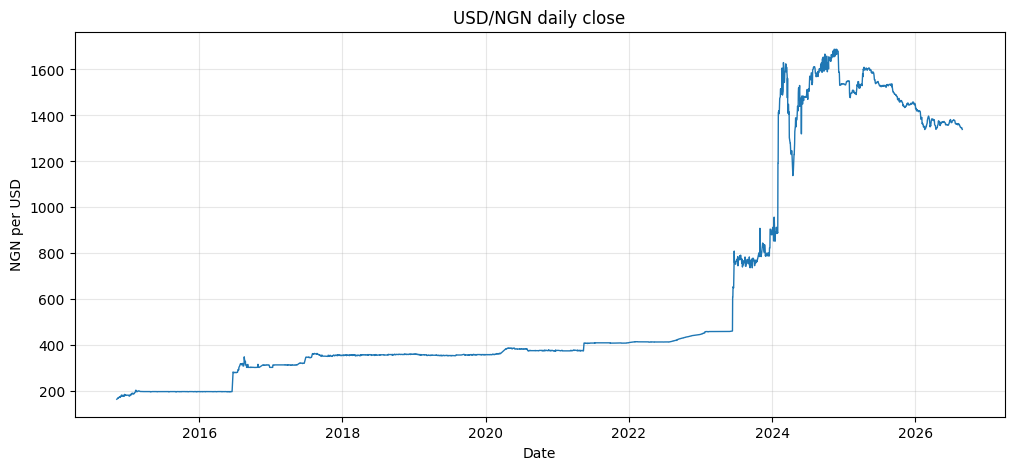

In [13]:
plt.figure(figsize=(12, 5))
plt.plot(master["date"], master["USDNGN_close"], linewidth=1)
plt.title("USD/NGN daily close")
plt.xlabel("Date")
plt.ylabel("NGN per USD")
plt.grid(alpha=0.3)
plt.show()

### 6.2 Daily volatility

Rolling 7-day standard deviation of the daily percentage change. Calm periods and turbulent periods should show up as distinct clusters, this is exactly the kind of feature that becomes an input in Stage 2.

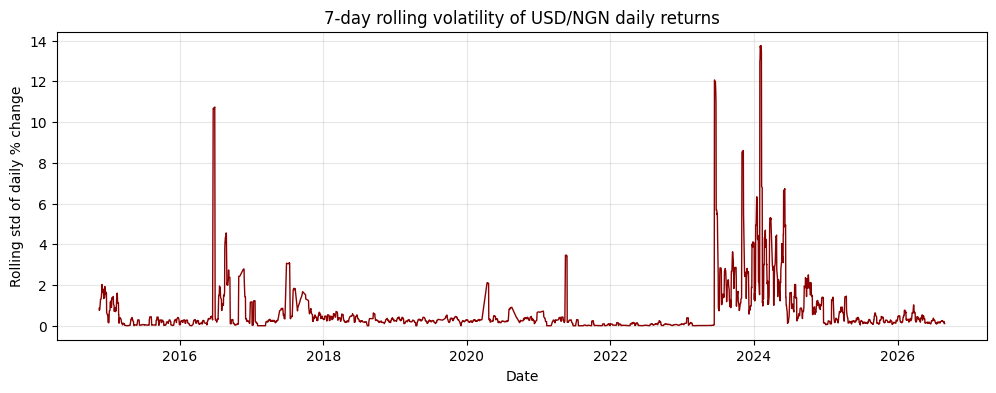

In [14]:
master["daily_return_pct"] = master["USDNGN_close"].pct_change() * 100
master["rolling_volatility_7d"] = master["daily_return_pct"].rolling(7).std()

plt.figure(figsize=(12, 4))
plt.plot(master["date"], master["rolling_volatility_7d"], linewidth=1, color="darkred")
plt.title("7-day rolling volatility of USD/NGN daily returns")
plt.xlabel("Date")
plt.ylabel("Rolling std of daily % change")
plt.grid(alpha=0.3)
plt.show()

### 6.3 Does oil price correlate with the exchange rate?

Nigeria's foreign exchange earnings are heavily tied to crude oil exports, so a meaningful negative correlation here (oil up, naira demand pressure down, rate more stable) would validate including oil price as a feature rather than just assuming it matters.

In [15]:
corr_cols = ["USDNGN_close", "wti_price", "brent_price", "us_inflation_pct"]
corr_matrix = master[corr_cols].corr()
corr_matrix

,USDNGN_close,wti_price,brent_price,us_inflation_pct
USDNGN_close,1.000000,0.380011,0.367933,0.129944
wti_price,0.380011,1.000000,0.987771,0.760260
brent_price,0.367933,0.987771,1.000000,0.738859
us_inflation_pct,0.129944,0.760260,0.738859,1.000000


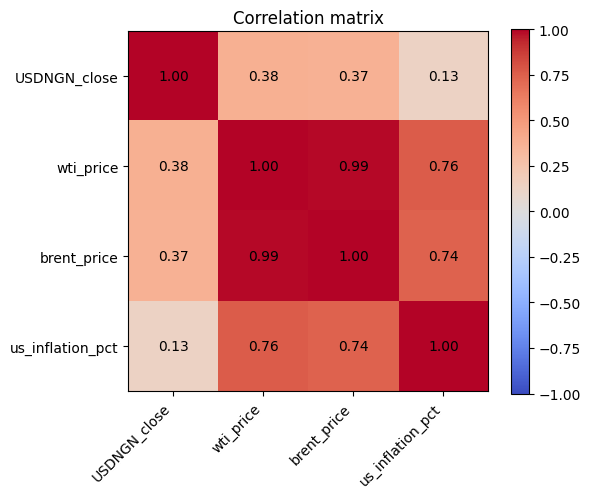

In [16]:
fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(corr_matrix, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr_cols)))
ax.set_yticks(range(len(corr_cols)))
ax.set_xticklabels(corr_cols, rotation=45, ha="right")
ax.set_yticklabels(corr_cols)
for i in range(len(corr_cols)):
    for j in range(len(corr_cols)):
        ax.text(j, i, f"{corr_matrix.iloc[i, j]:.2f}", ha="center", va="center")
plt.colorbar(im)
plt.title("Correlation matrix")
plt.tight_layout()
plt.show()

### 6.4 Summary statistics

In [17]:
master[["USDNGN_close", "wti_price", "brent_price", "daily_return_pct"]].describe()

,USDNGN_close,wti_price,brent_price,daily_return_pct
count,2809.000000,2809.000000,2809.000000,2808.000000
mean,637.751588,64.825176,69.104258,0.085777
std,492.553856,18.062931,19.423696,1.574143
min,165.750000,-36.980000,9.120000,-13.414484
25%,355.000000,51.660000,55.600000,-0.065328
50%,385.000000,63.910000,68.830000,0.000000
75%,824.000000,76.010000,80.530000,0.100604
max,1687.784000,123.640000,138.210000,34.088557


## 7. Stage 1 checklist

- [x] Raw data pulled from a live API, cached locally, not a Kaggle download
- [x] Parsing logic handles both Alpha Vantage response shapes
- [x] Series merged on date with the correct strategy for daily vs. annual data
- [x] Missing values identified and handled with a documented, defensible method (forward-fill)
- [x] Master dataset saved to `processed_data/naira_pulse_master.csv`
- [x] Initial exploration: trend, volatility, correlation with oil, summary stats

**Feeds directly into your Executive Summary:**
- *Overview*: "Naira Pulse pulls live USD/NGN, crude oil, and macro data via the Alpha Vantage API..."
- *Problem*: the volatility chart in section 6.2 is your strongest visual evidence that the rate moves unpredictably enough to justify a forecasting tool.

**Next: Stage 2** picks up from `processed_data/naira_pulse_master.csv`, engineers the lag/rolling/calendar features, and defines the classification target (naira weakens more than 1% over the next 7 days, yes/no).
